In [37]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
train_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/train_dataset.csv")
test_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/test_without_gt.csv")
submission_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/submission_template_for_test.csv")

##

In [39]:
# Normalie
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Support Vector Machine
from sklearn.svm import SVC

# Tree-base model
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier

In [40]:
# Evaluation and reported mreticss
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score, matthews_corrcoef, precision_recall_curve
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance

In [41]:
# Syntetucs data 
from imblearn.over_sampling import SMOTE, RandomOverSampler, ADASYN
from imblearn.under_sampling import RandomUnderSampler, EditedNearestNeighbours, RepeatedEditedNearestNeighbours

##

## Feature Engineer

In [42]:
feature_baseline = [
       '12-Month Default Flag','Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'
    
]

In [43]:
# ==========================================
# 1. ORIGINAL FEATURES
# ==========================================

def original_feature_func(df):

    income = df['Declared Annual Income']
    borrowing = df['Declared Borrowing Amount']
    credit = df['Desired Credit Limit']
    num_borrowings = df['Declared Number of Borrowings']

    age = df['Age (in months)']
    residence = df['Residence Period (in months)']
    dependents = df['Number of Dependents']

    rent = df['Rent Burden']

    features = pd.DataFrame(index=df.index)

    features['Zero_Income_Flag'] = income.eq(0).astype('int8')
    features['Zero_Borrowing_Flag'] = borrowing.eq(0).astype('int8')
    features['Zero_Credit_Flag'] = credit.eq(0).astype('int8')

    features['Credit_Income_Ratio'] = (
        credit / income.where(income > 0)
    )

    features['Borrowing_Income_Ratio'] = (
        borrowing / income.where(income > 0)
    )

    features['Exposure_To_Income'] = (
        (borrowing + credit) / income.where(income > 0)
    )

    features['Avg_Borrowing_Per_Loan'] = (
        borrowing / num_borrowings.where(num_borrowings > 0)
    )

    features['Limit_To_Borrow'] = (
        credit / borrowing.where(borrowing > 0)
    )

    features['Rent_To_Income'] = (
        rent / income.where(income > 0)
    )

    features['Income_Per_Dependent'] = (
        income / (dependents + 1)
    )

    features['Children_Share'] = (
        df['Number of Dependent Children']
        / dependents.where(dependents > 0)
    )

    features['Residence_Stability_Ratio'] = (
        residence / age.where(age > 0)
    )

    features['Age_When_Moved'] = age - residence

    # Special cases
    features.loc[
        income.eq(0) & credit.eq(0),
        'Credit_Income_Ratio'
    ] = 0

    features.loc[
        income.eq(0) & borrowing.eq(0),
        'Borrowing_Income_Ratio'
    ] = 0

    features.loc[
        borrowing.eq(0) & credit.eq(0),
        'Limit_To_Borrow'
    ] = 0

    features.loc[
        num_borrowings.eq(0) & borrowing.eq(0),
        'Avg_Borrowing_Per_Loan'
    ] = 0

    features.loc[
        income.eq(0) & borrowing.eq(0) & credit.eq(0),
        'Exposure_To_Income'
    ] = 0

    features.loc[
        income.eq(0) & rent.eq(0),
        'Rent_To_Income'
    ] = 0

    return features.replace([np.inf, -np.inf], np.nan)


# ==========================================
# 2. FINANCIAL FEATURES
# ==========================================

def financial_feature_func(df):

    income = df['Declared Annual Income']
    borrowing = df['Declared Borrowing Amount']
    rent = df['Rent Burden']
    num_borrowings = df['Declared Number of Borrowings']
    dependents = df['Number of Dependents']

    features = pd.DataFrame(index=df.index)

    features['Total_Burden_Ratio'] = (
        (borrowing + rent) / income.where(income > 0)
    )

    features['Net_Income_After_Rent'] = (
        income - rent
    )

    features['Net_Income_Per_Dependent'] = (
        (income - rent) / (dependents + 1)
    )

    features['Debt_Per_Dependent'] = (
        borrowing / (dependents + 1)
    )

    features['Rent_Per_Dependent'] = (
        rent / (dependents + 1)
    )

    features['Income_Per_Loan'] = (
        income / num_borrowings.where(num_borrowings > 0)
    )

    return features.replace([np.inf, -np.inf], np.nan)


# ==========================================
# 3. CONTACT FEATURES
# ==========================================

def contact_feature_func(df):

    phone_cols = [
        'Home Phone Number Available',
        'Mobile Phone Number Available',
        'Employer Phone Number Available',
        'Driver Licence Number Available'
    ]

    phone_data = df[phone_cols].apply(
        pd.to_numeric,
        errors='coerce'
    )

    features = pd.DataFrame(index=df.index)

    features['Contact_Count'] = phone_data.sum(axis=1)

    features['Contact_Completeness'] = (
        phone_data.mean(axis=1)
    )

    features['Contact_Fields_Missing_Count'] = (
        phone_data.isna().sum(axis=1)
    )

    features['Has_Personal_Contact'] = (
        phone_data[
            [
                'Home Phone Number Available',
                'Mobile Phone Number Available'
            ]
        ].max(axis=1)
    )

    return features


# ==========================================
# 4. INTERACTION FEATURES
# ==========================================

def interaction_feature_func(df):

    features = pd.DataFrame(index=df.index)

    interaction_pairs = [
        (
            'Employment Type Category',
            'Company Size Category', # Company type data
            'Employment_Company_Interaction'
        ),
        (
            'Industry Category',
            'Business Entity Type', #
            'Industry_Business_Interaction'
        ),
        (
            'Occupation Category',
            'Employment Type Category',
            'Occupation_Employment_Interaction'
        )
    ]

    for col1, col2, new_col in interaction_pairs:

        features[new_col] = (
            df[col1].astype('string').fillna('__MISSING__')
            + '_'
            + df[col2].astype('string').fillna('__MISSING__')
        ).astype('category')

    return features


# ==========================================
# 5. MISSING FEATURES
# ==========================================

def missing_feature_func(df):

    missing_cols = [
        'Declared Annual Income',
        'Declared Borrowing Amount',
        'Desired Credit Limit',
        'Declared Number of Borrowings',
        'Rent Burden',
        'Age (in months)',
        'Residence Period (in months)',
        'Number of Dependents',
        'Number of Dependent Children'
    ]

    features = pd.DataFrame(index=df.index)

    for col in missing_cols:

        features[f'{col}_Missing'] = (
            df[col].isna().astype('int8')
        )

    return features


# ==========================================
# 6. LOG FEATURES
# ==========================================

def log_feature_func(df):

    log_cols = [
        'Declared Annual Income',
        'Declared Borrowing Amount',
        'Desired Credit Limit',
        'Rent Burden',
        'Declared Number of Borrowings'
    ]

    features = pd.DataFrame(index=df.index)

    for col in log_cols:

        features[f'{col}_Log1p'] = np.log1p(
            df[col].clip(lower=0)
        )

    return features.replace([np.inf, -np.inf], np.nan)

# ==============================================
# 7. Frequency Encoding
# ==============================================

def frequency_encoding_func(fit_df, transform_df=None):

    transform_df = fit_df
    features = pd.DataFrame(index=transform_df.index)

    # ----------------------------------
    # 1. BASIC FREQUENCY + RARITY
    # ----------------------------------

    single_cols = [
        'Company Size Category',
        'Occupation Category',
        'Application Channel',
        'Employment Type Category',
        'Industry Category',
        'Business Entity Type'
    ]

    missing_token = '__MISSING__'

    def normalize_col(df, col):
        return df[col].astype(object).where(
            df[col].notna(), missing_token
        )

    for col in single_cols:

        train_values = normalize_col(fit_df, col)
        test_values = normalize_col(transform_df, col)

        freq_map = train_values.value_counts(
            normalize=True,
            dropna=False
        ).to_dict()

        freq = test_values.map(freq_map).fillna(0)

        features[f'{col}_freq'] = freq
        features[f'{col}_rarity'] = -np.log(
            freq.clip(lower=1e-10)
        )

    # ----------------------------------
    # 2. JOINT + CONDITIONAL FREQUENCY
    # ----------------------------------

    pairs = [
        (
            'Employment Type Category',
            'Company Size Category',
            'Employment_Company'
        ),
        (
            'Occupation Category',
            'Employment Type Category',
            'Occupation_Employment'
        ),
        (
            'Industry Category',
            'Business Entity Type',
            'Industry_Entity'
        ),
        (
            'Company Size Category',
            'Occupation Category',
            'Company_Occupation'
        )
    ]

    for col1, col2, name in pairs:

        train_a = normalize_col(fit_df, col1)
        train_b = normalize_col(fit_df, col2)

        test_a = normalize_col(transform_df, col1)
        test_b = normalize_col(transform_df, col2)

        train_pairs = list(zip(train_a, train_b))
        test_pairs = list(zip(test_a, test_b))

        # Joint Frequency: P(A, B)
        joint_counts = pd.Series(
            train_pairs
        ).value_counts()

        joint_map = (
            joint_counts / len(fit_df)
        ).to_dict()

        features[f'{name}_joint_freq'] = (
            pd.Series(test_pairs, index=transform_df.index)
            .map(joint_map)
            .fillna(0)
        )

        # Conditional Frequency: P(A | B)
        context_counts = train_b.value_counts().to_dict()

        conditional_map = {
            pair: count / context_counts[pair[1]]
            for pair, count in joint_counts.items()
        }

        features[f'{name}_conditional_freq'] = (
            pd.Series(test_pairs, index=transform_df.index)
            .map(conditional_map)
            .fillna(0)
        )

    return features



# ==============================================
# 7. Gender interaction
# ==============================================
#def Gender_interaction_func(df):
    


In [44]:

def build_features(
    df,
    groups=None,
    baseline_features=None
):

    if groups is None:
        groups = [
            'original',
            'financial',
            'contact',
            'interaction',
            'missing',
            'log'
        ]

    feature_functions = {
        'original': original_feature_func,
        'financial': financial_feature_func,
        'contact': contact_feature_func,
        'interaction': interaction_feature_func,
        'missing': missing_feature_func,
        'log': log_feature_func,
        'freq': frequency_encoding_func
    }

    result = []

    # Original dataset features
    if baseline_features is not None:
        result.append(df[baseline_features].copy())

    # Selected engineered features
    for group in groups:

        if group not in feature_functions:
            raise ValueError(
                f"Unknown feature group: {group}"
            )

        group_features = feature_functions[group](df)

        result.append(group_features)

    if len(result) == 0:
        return pd.DataFrame(index=df.index)

    X = pd.concat(result, axis=1)

    # Prevent duplicated column names
    if X.columns.duplicated().any():
        duplicates = X.columns[X.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate features: {duplicates}")

    return X


In [ ]:
EXPERIMENTS = {

    'baseline': [],

    'original': [
        'original'
    ],

    'financial': [
        'original',
        'financial'
    ],

    'contact': [
        'original',
        'contact'
    ],

    'interaction': [
        'original',
        'interaction'
    ],

    'financial_contact': [
        'original',
        'financial',
        'contact'
    ],

    'all_features': [
        'original',
        'financial',
        'contact',
        'interaction',
        'missing',
        'log'
    ],

    'financial_frequency':[
        'original',
        'financial',
        'freq',
        'interaction',
    ]
}


X_experiments = {
    name: build_features(
        df,
        groups=groups,
        baseline_features=feature_baseline
    )
    for name, groups in EXPERIMENTS.items()
}


# Inspect feature counts
for name, X in X_experiments.items():

    print(
        f'{name:25s} | '
        f'Features: {X.shape[1]} | '
        f'Shape: {X.shape}'
    )



baseline                  | Features: 26 | Shape: (68546, 26)
original                  | Features: 39 | Shape: (68546, 39)
financial                 | Features: 45 | Shape: (68546, 45)
contact                   | Features: 43 | Shape: (68546, 43)
interaction               | Features: 42 | Shape: (68546, 42)
financial_contact         | Features: 49 | Shape: (68546, 49)
all_features              | Features: 66 | Shape: (68546, 66)
financial_frequency       | Features: 68 | Shape: (68546, 68)


##

## Syntetics Data

In [46]:
""""
        'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'
"""
original_feature = [
        "Declared Annual Income",
        "Declared Borrowing Amount",
        "Desired Credit Limit",
        "Declared Number of Borrowings",
        "Age (in months)",
        "Residence Period (in months)",
        "Rent Burden",
        "Occupation Category",
        "Industry Category",
        "Application Channel",
        "Company Size Category",
        "Number of Dependents",
        "Employment Type Category",#..
        "Residence Ownership Status"
    
    ]
target_col = ["12-Month Default Flag"]

In [47]:
def Split_datamodel_func(f_x, f_y, size_test=0.2):

    x_train, x_val, y_train, y_val = train_test_split(
        f_x,
        f_y,
        test_size=size_test,
        random_state=42,
        stratify=f_y
    )

    print("Train:", x_train.shape, y_train.shape)
    print("Validation:", x_val.shape, y_val.shape)

    print("\nTrain Distribution:")
    print(pd.Series(y_train).value_counts(normalize=True))

    print("\nValidation Distribution:")
    print(pd.Series(y_val).value_counts(normalize=True))

    return x_train, x_val, y_train, y_val

In [48]:
df = train_data.copy()

In [49]:
df['12-Month Default Flag'].value_counts()

12-Month Default Flag
0    61913
1     6633
Name: count, dtype: int64

In [50]:
smote = SMOTE(
    #sampling_strategy=0.5,
    #k_neighbors=5,
    random_state=42
)

under = RandomUnderSampler(random_state=42)

over = RandomOverSampler(random_state=42)

editN = EditedNearestNeighbours()

In [51]:
X_train, x_test, y_train, y_test = Split_datamodel_func(df[original_feature],df["12-Month Default Flag"])

Train: (54836, 14) (54836,)
Validation: (13710, 14) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64


In [52]:
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
X_train_smote.shape , y_train_smote.shape

((99060, 14), (99060,))

In [53]:
X_train_under, y_train_under = under.fit_resample(X_train, y_train)
X_train_under.shape , y_train_under.shape

((10612, 14), (10612,))

In [54]:
X_train_over, y_train_over= over.fit_resample(X_train, y_train)
X_train_over.shape , y_train_over.shape

((99060, 14), (99060,))

In [55]:
X_train_edit, y_train_edit= editN.fit_resample(X_train, y_train)
X_train_edit.shape , y_train_edit.shape

((41799, 14), (41799,))

In [56]:
y_train_smote.value_counts()

12-Month Default Flag
0    49530
1    49530
Name: count, dtype: int64

In [57]:
y_train_under.value_counts()

12-Month Default Flag
0    5306
1    5306
Name: count, dtype: int64

In [58]:
y_train_over.value_counts()

12-Month Default Flag
0    49530
1    49530
Name: count, dtype: int64

In [59]:
y_train_edit.value_counts()

12-Month Default Flag
0    36493
1     5306
Name: count, dtype: int64

##

##

##

## The gobal a machine learning classification

In [60]:
# ==========================================
# MODEL TRAINING + CROSS VALIDATION
# ==========================================

def train_evaluate_model(
    classifier,
    x_train,
    y_train,
    x_test,
    y_test,
    n_splits=5,
    n_repeats=2
):

    cv = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=42
    )

    # 1. Cross Validation
    cv_scores = cross_val_score(
        classifier,
        x_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=1
    )

    print("CV ROC-AUC:",
          f"{cv_scores.mean():.4f}")

    print("CV STD:",
          f"{cv_scores.std():.4f}")

    # 2. Train Model
    classifier.fit(x_train, y_train)

    # 3. Find Positive Class
    pos_idx = np.where(classifier.classes_ == 1)[0][0]

    # 4. Probability Prediction
    y_prob = classifier.predict_proba(x_test)[:, pos_idx]

    # 5. Evaluation
    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    print("\nValidation ROC-AUC:", f"{auc:.4f}")
    print("Validation PR-AUC:", f"{pr_auc:.4f}")

    # 6. ROC Curve
    RocCurveDisplay.from_predictions(y_test, y_prob)

    plt.title(f"ROC Curve (AUC = {auc:.4f})")
    plt.grid(alpha=0.3)
    plt.show()

    return classifier, y_prob, cv_scores


# ==========================================
# MODEL EVALUATION
# ==========================================

def model_evaluation(
    classifier,
    x_test,
    y_test,
    threshold=0.5,
    y_prob=None
):

    if y_prob is None:
        pos_idx = np.where(classifier.classes_ == 1)[0][0]
        y_prob = classifier.predict_proba(x_test)[:, pos_idx]

    y_pred = (y_prob >= threshold).astype(int)

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    names = [
        "True Neg",
        "False Pos",
        "False Neg",
        "True Pos"
    ]

    counts = cm.flatten()

    percentages = [
        f"{v:.2%}" for v in counts / counts.sum()
    ]

    labels = [
        f"{name}\n{count}\n{percent}"
        for name, count, percent in zip(
            names, counts, percentages
        )
    ]

    labels = np.asarray(labels).reshape(2, 2)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="rocket_r",
        cbar=True
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix (Threshold = {threshold})")
    plt.show()

    # Classification Report
    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    # Additional Metrics
    print("ROC-AUC:",
          roc_auc_score(y_test, y_prob))

    print("PR-AUC:",
          average_precision_score(y_test, y_prob))

    print("MCC:",
          matthews_corrcoef(y_test, y_pred))

    return y_pred


# ==========================================
# FEATURE IMPORTANCE
# ==========================================

def feature_importance_func(model, feature):

    if not hasattr(model, "feature_importances_"):
        raise ValueError("This model does not support feature_importances_")

    plot_importances = pd.Series(
        model.feature_importances_,
        index=feature
    )

    plot_importances.sort_values(
        ascending=True,
        inplace=True
    )

    plt.figure(figsize=(10, 7))

    plot_importances.plot(kind="barh")

    plt.title("Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

In [61]:
xgb_model = XGBClassifier(

    # Learning
    n_estimators=1000,
    learning_rate=0.025,

    # Tree Architecture
    max_depth=5,
    grow_policy='depthwise',
    tree_method='hist',

    # Regularization & Pruning
    min_child_weight=3,
    gamma=0.05,

    # Sampling
    subsample=0.85,
    colsample_bytree=0.85,

    # L1 / L2 Regularization
    reg_alpha=0.1,
    reg_lambda=3.0,

    # Imbalance Handling
    scale_pos_weight=1,

    # Objective
    objective='binary:logistic',
    eval_metric='aucpr',

    # System
    n_jobs=-1,
    random_state=42
)

cat_model = CatBoostClassifier(

    # Learning
    iterations=1500,
    learning_rate=0.025,

    # Tree Architecture
    depth=5,
    grow_policy='SymmetricTree',

    # Regularization
    l2_leaf_reg=7.0,
    random_strength=1.0,

    # Sampling
    bootstrap_type='Bernoulli',
    subsample=0.85,

    # Numerical Features
    border_count=128,

    # Imbalance
    auto_class_weights=None,

    # Objective
    loss_function='Logloss',
    eval_metric='PRAUC',

    # Training
    leaf_estimation_iterations=5,

    # System
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1
)

lgbm_model = LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.025,

    max_depth=5,
    num_leaves=16,

    min_child_samples=100,
    min_child_weight=1e-2,
    min_split_gain=0.02,

    subsample=0.80,
    subsample_freq=1,
    colsample_bytree=0.75,

    reg_alpha=0.5,
    reg_lambda=5.0,

    n_jobs=-1,
    verbose=-1,
)



CV ROC-AUC: 0.6215
CV STD: 0.0074

Validation ROC-AUC: 0.6325
Validation PR-AUC: 0.1467


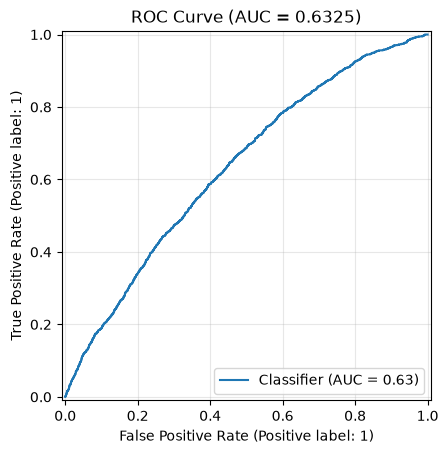

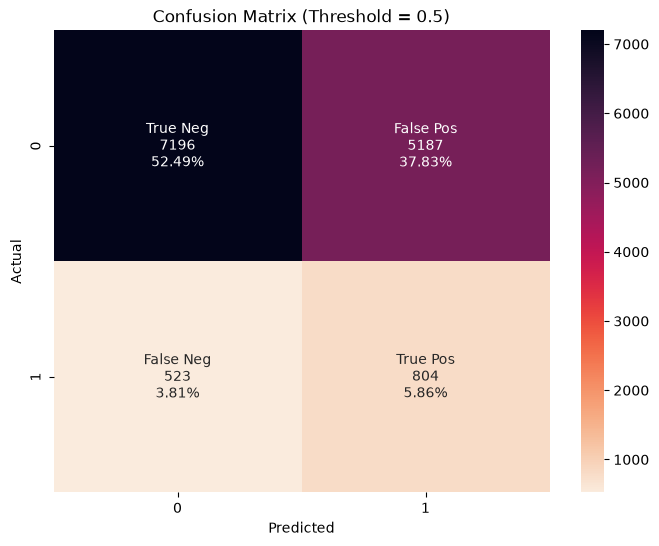


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.58      0.72     12383
           1       0.13      0.61      0.22      1327

    accuracy                           0.58     13710
   macro avg       0.53      0.59      0.47     13710
weighted avg       0.86      0.58      0.67     13710

ROC-AUC: 0.6324958963296606
PR-AUC: 0.14668267547059716
MCC: 0.11146879678539756


In [62]:
# lightgbm
# CatBoost
lgbm_clf, y_prob, cv_scores = train_evaluate_model(
    lgbm_model,
    X_train_under,
    y_train_under,
    x_test,
    y_test
)

y_pred = model_evaluation(
    lgbm_clf,
    x_test,
    y_test,
    threshold=0.5,
    y_prob=y_prob
)

CV ROC-AUC: 0.6228
CV STD: 0.0071

Validation ROC-AUC: 0.6332
Validation PR-AUC: 0.1468


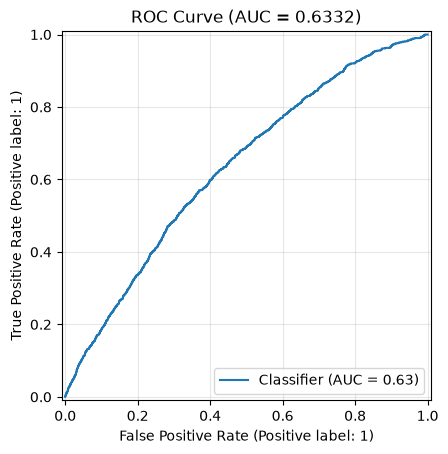

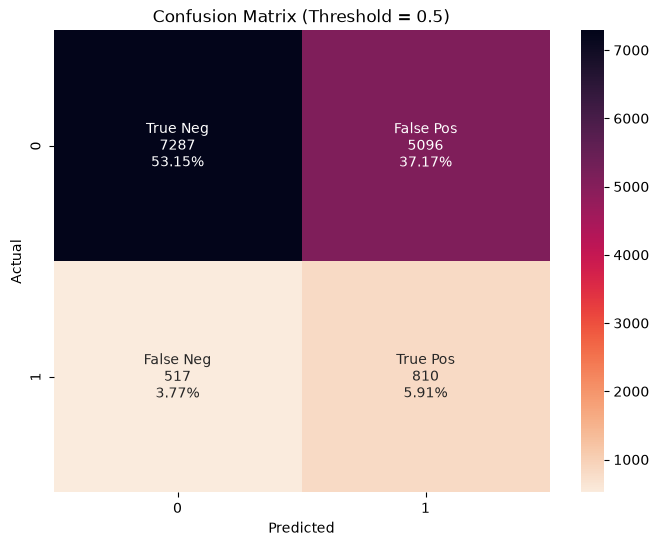


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.59      0.72     12383
           1       0.14      0.61      0.22      1327

    accuracy                           0.59     13710
   macro avg       0.54      0.60      0.47     13710
weighted avg       0.86      0.59      0.67     13710

ROC-AUC: 0.6332085806190404
PR-AUC: 0.1468173132672299
MCC: 0.11874265879320106


In [73]:
# CatBoost
cat_clf, y_prob, cv_scores = train_evaluate_model(
    xgb_model,
    X_train_under,
    y_train_under,
    x_test,
    y_test
)

y_pred = model_evaluation(
    cat_clf,
    x_test,
    y_test,
    threshold=0.50,
    y_prob=y_prob
)

In [70]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef,
    balanced_accuracy_score
)

thresholds = np.arange(0.30, 0.81, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "FPR": fp / (fp + tn),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df.round(4)
)

,Threshold,Precision,Recall,F1,Specificity,FPR,MCC,FP,FN
0,0.30,0.1072,0.9450,0.1926,0.1570,0.8430,0.0851,10439,73
1,0.35,0.1122,0.8907,0.1993,0.2449,0.7551,0.0951,9350,145
2,0.40,0.1183,0.8101,0.2065,0.3531,0.6469,0.1020,8011,252
3,0.45,0.1266,0.7159,0.2152,0.4709,0.5291,0.1110,6552,377
4,0.50,0.1371,0.6104,0.2240,0.5885,0.4115,0.1187,5096,517
5,0.55,0.1470,0.4876,0.2259,0.6968,0.3032,0.1168,3754,680
6,0.60,0.1509,0.3466,0.2102,0.7909,0.2091,0.0978,2589,867
7,0.65,0.1614,0.2419,0.1936,0.8653,0.1347,0.0900,1668,1006
8,0.70,0.1749,0.1492,0.1610,0.9246,0.0754,0.0793,934,1129
9,0.75,0.1987,0.0889,0.1229,0.9616,0.0384,0.0733,476,1209


CV ROC-AUC: 0.6228
CV STD: 0.0071

Validation ROC-AUC: 0.6332
Validation PR-AUC: 0.1468


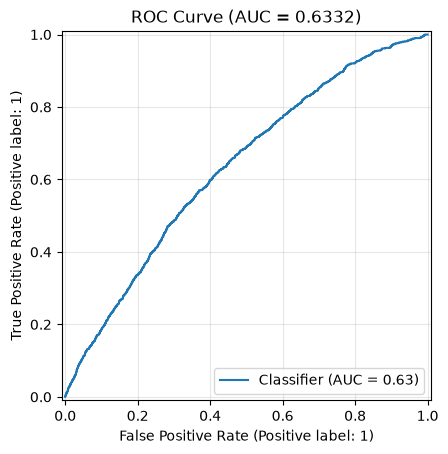

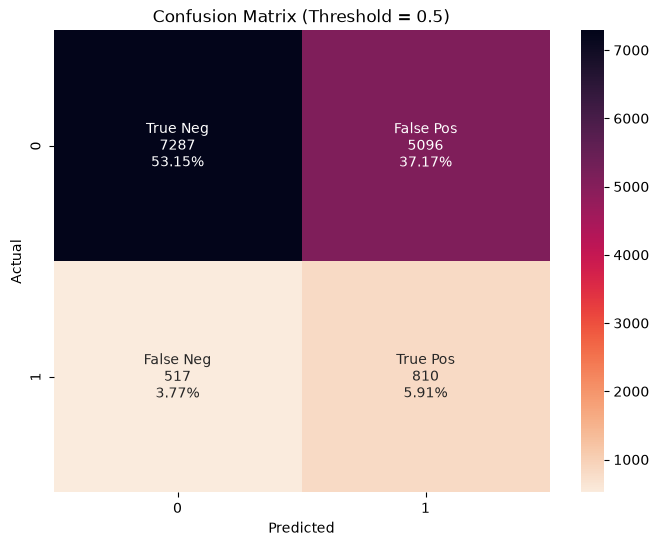


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.59      0.72     12383
           1       0.14      0.61      0.22      1327

    accuracy                           0.59     13710
   macro avg       0.54      0.60      0.47     13710
weighted avg       0.86      0.59      0.67     13710

ROC-AUC: 0.6332085806190404
PR-AUC: 0.1468173132672299
MCC: 0.11874265879320106


In [64]:
# Xgboost
xgb_clf, y_prob, cv_scores = train_evaluate_model(
    xgb_model,
    X_train_under,
    y_train_under,
    x_test,
    y_test
)

y_pred = model_evaluation(
    xgb_clf,
    x_test,
    y_test,
    threshold=0.5,
    y_prob=y_prob
)

In [65]:
print("Original Training:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nValidation:")
print(y_test.value_counts())

print("\nPredicted Probability:")
print(pd.Series(y_prob).describe())

Original Training:
12-Month Default Flag
0    49530
1     5306
Name: count, dtype: int64

After SMOTE:
12-Month Default Flag
0    49530
1    49530
Name: count, dtype: int64

Validation:
12-Month Default Flag
0    12383
1     1327
Name: count, dtype: int64

Predicted Probability:
count    13710.000000
mean         0.473304
std          0.158447
min          0.021749
25%          0.359398
50%          0.469508
75%          0.585217
max          0.952630
dtype: float64


In [66]:
X_experiments[name]

,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,Company Size Category,Business Entity Type,Declared Annual Income,Payday,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Zero_Income_Flag,Zero_Borrowing_Flag,Zero_Credit_Flag,Credit_Income_Ratio,Borrowing_Income_Ratio,Exposure_To_Income,Avg_Borrowing_Per_Loan,Limit_To_Borrow,Rent_To_Income,Income_Per_Dependent,Children_Share,Residence_Stability_Ratio,Age_When_Moved,Total_Burden_Ratio,Net_Income_After_Rent,Net_Income_Per_Dependent,Debt_Per_Dependent,Rent_Per_Dependent,Income_Per_Loan,Company Size Category_freq,Company Size Category_rarity,Occupation Category_freq,Occupation Category_rarity,Application Channel_freq,Application Channel_rarity,Employment Type Category_freq,Employment Type Category_rarity,Industry Category_freq,Industry Category_rarity,Business Entity Type_freq,Business Entity Type_rarity,Employment_Company_joint_freq,Employment_Company_conditional_freq,Occupation_Employment_joint_freq,Occupation_Employment_conditional_freq,Industry_Entity_joint_freq,Industry_Entity_conditional_freq,Company_Occupation_joint_freq,Company_Occupation_conditional_freq,Employment_Company_Interaction,Industry_Business_Interaction,Occupation_Employment_Interaction
0,0,18,1,2,699,141,140,8,6,4,8,9,4800000,10,3,1400000,300000,1,50000,1,2,1,1,1,1,1,0,0,0,0.062500,0.291667,0.354167,466666.666667,0.214286,0.010417,1600000.0,0.5,0.201717,558,0.302083,4750000,1.583333e+06,466666.666667,16666.666667,1600000.0,0.097934,2.323459,0.097263,2.330335,0.205876,1.580480,0.064657,2.738654,0.163292,1.812216,0.694585,0.364441,0.022029,0.224937,0.015683,0.242554,0.124092,0.178656,0.014647,0.150592,6_8,8_9,140_6
1,0,20,2,2,419,26,640,1,1,3,3,0,3500000,25,4,600000,200000,3,0,0,1,0,0,1,0,0,0,0,0,0.057143,0.171429,0.228571,150000.000000,0.333333,0.000000,1750000.0,0.0,0.062053,393,0.171429,3500000,1.750000e+06,300000.000000,0.000000,875000.0,0.152744,1.878991,0.298573,1.208740,0.308639,1.175581,0.588189,0.530707,0.131386,2.029614,0.300514,1.202263,0.090494,0.592455,0.185598,0.315541,0.041593,0.138405,0.044817,0.150103,1_3,1_0,640_1
2,0,1,2,1,322,181,540,8,5,1,6,9,1560000,15,1,180000,100000,1,0,3,0,0,0,1,1,1,0,0,0,0.064103,0.115385,0.179487,180000.000000,0.555556,0.000000,1560000.0,NaN,0.562112,141,0.115385,1560000,1.560000e+06,180000.000000,0.000000,1560000.0,0.137616,1.983291,0.213448,1.544362,0.072098,2.629735,0.231990,1.461060,0.163292,1.812216,0.694585,0.364441,0.039565,0.287501,0.120488,0.519369,0.124092,0.178656,0.030709,0.143873,5_6,8_9,540_5
3,0,17,1,1,328,328,640,1,5,3,5,9,1800000,12,2,500000,100000,1,0,3,0,0,1,1,1,1,0,0,0,0.055556,0.277778,0.333333,250000.000000,0.200000,0.000000,1800000.0,NaN,1.000000,0,0.277778,1800000,1.800000e+06,500000.000000,0.000000,900000.0,0.129388,2.044943,0.298573,1.208740,0.413387,0.883372,0.231990,1.461060,0.131386,2.029614,0.694585,0.364441,0.030461,0.235427,0.051921,0.223808,0.088948,0.128059,0.045955,0.153914,5_5,1_9,640_5
4,1,18,1,1,451,44,1040,16,1,1,5,9,5000000,21,1,1000000,100000,4,60000,0,0,0,0,1,1,1,0,0,0,0.020000,0.200000,0.220000,1000000.000000,0.100000,0.012000,5000000.0,NaN,0.097561,407,0.212000,4940000,4.940000e+06,1000000.000000,60000.000000,5000000.0,0.129388,2.044943,0.020103,3.906872,0.205876,1.580480,0.588189,0.530707,0.021402,3.844286,0.694585,0.364441,0.082543,0.637952,0.017988,0.030582,0.015727,0.022642,0.000540,0.026851,1_5,16_9,1040_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

Experiment: baseline
Train: (54836, 25) (54836,)
Validation: (13710, 25) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64
0:	learn: 0.4078746	total: 1.26ms	remaining: 1.89s
100:	learn: 0.4827011	total: 145ms	remaining: 2.01s
200:	learn: 0.5054428	total: 290ms	remaining: 1.88s
300:	learn: 0.5244312	total: 437ms	remaining: 1.74s
400:	learn: 0.5426086	total: 581ms	remaining: 1.59s
500:	learn: 0.5646535	total: 724ms	remaining: 1.44s
600:	learn: 0.5843931	total: 870ms	remaining: 1.3s
700:	learn: 0.6037681	total: 1.02s	remaining: 1.16s
800:	learn: 0.6208324	total: 1.17s	remaining: 1.02s
900:	learn: 0.6365717	total: 1.31s	remaining: 870ms
1000:	learn: 0.6514246	total: 1.45s	remaining: 724ms
1100:	learn: 0.6652797	total: 1.6s	remaining: 579ms
1200:	learn: 0.6775669	total: 1.74s	remaining: 434ms
1300:	learn: 0.6898431	total:

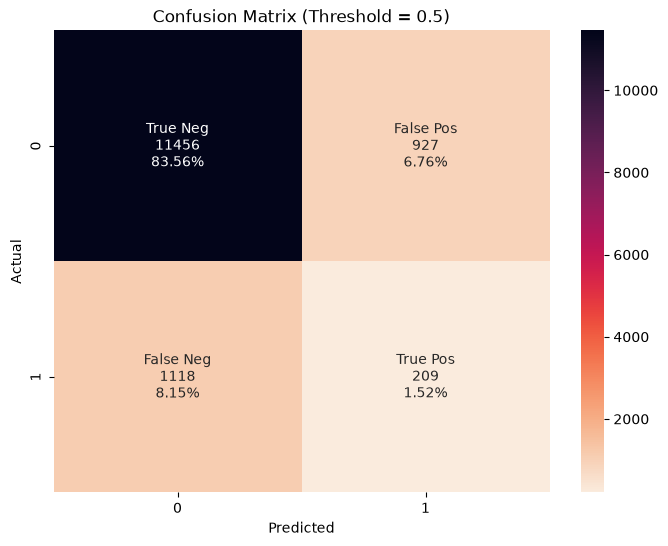


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92     12383
           1       0.18      0.16      0.17      1327

    accuracy                           0.85     13710
   macro avg       0.55      0.54      0.54     13710
weighted avg       0.84      0.85      0.85     13710

ROC-AUC: 0.6505754753718619
PR-AUC: 0.1554177191304313
MCC: 0.08863377640158741

Experiment baseline completed!
Experiment: original
Train: (54836, 38) (54836,)
Validation: (13710, 38) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64
0:	learn: 0.4005965	total: 1.91ms	remaining: 2.86s
100:	learn: 0.4860063	total: 154ms	remaining: 2.13s
200:	learn: 0.5123042	total: 308ms	remaining: 1.99s
300:	learn: 0.5328545	total: 459ms	remaining: 1.83s
400:	learn: 0.5521425	total: 610ms	

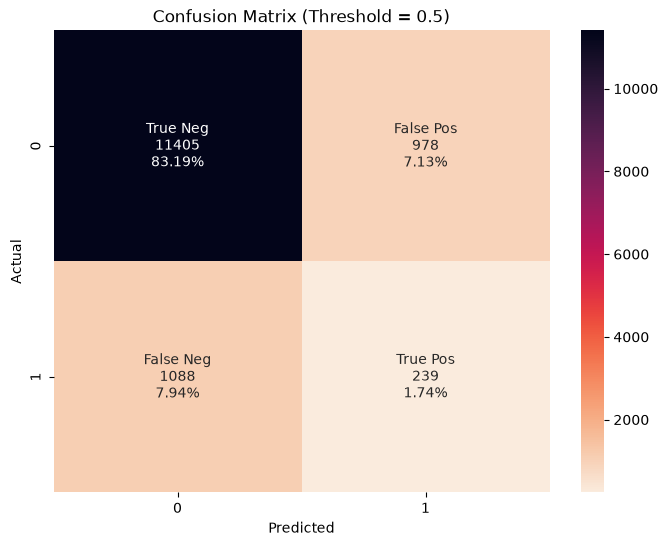


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.92      0.92     12383
           1       0.20      0.18      0.19      1327

    accuracy                           0.85     13710
   macro avg       0.55      0.55      0.55     13710
weighted avg       0.84      0.85      0.85     13710

ROC-AUC: 0.6518261873106657
PR-AUC: 0.15730238078751813
MCC: 0.10513169460623309

Experiment original completed!
Experiment: financial
Train: (54836, 44) (54836,)
Validation: (13710, 44) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64
0:	learn: 0.4030060	total: 1.3ms	remaining: 1.95s
100:	learn: 0.4888905	total: 156ms	remaining: 2.17s
200:	learn: 0.5153300	total: 317ms	remaining: 2.05s
300:	learn: 0.5349106	total: 474ms	remaining: 1.89s
400:	learn: 0.5547916	total: 633ms

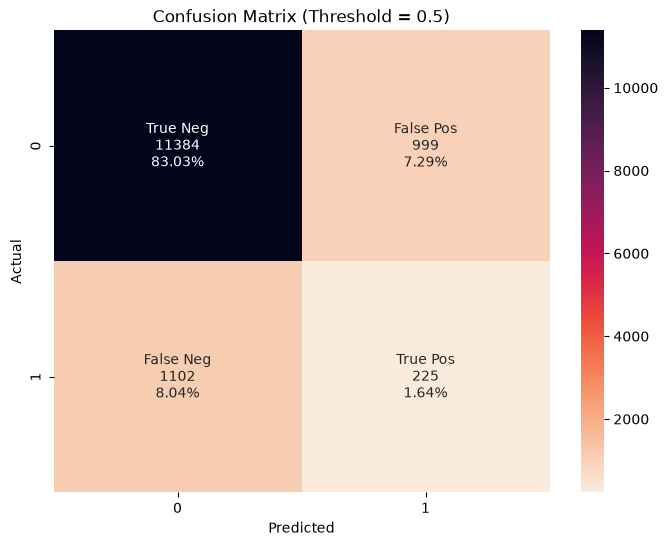


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.92      0.92     12383
           1       0.18      0.17      0.18      1327

    accuracy                           0.85     13710
   macro avg       0.55      0.54      0.55     13710
weighted avg       0.84      0.85      0.84     13710

ROC-AUC: 0.6503616274858677
PR-AUC: 0.15493592289253716
MCC: 0.09216189244364886

Experiment financial completed!
Experiment: contact
Train: (54836, 42) (54836,)
Validation: (13710, 42) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64
0:	learn: 0.3909067	total: 1.24ms	remaining: 1.86s
100:	learn: 0.4867028	total: 154ms	remaining: 2.13s
200:	learn: 0.5087922	total: 307ms	remaining: 1.98s
300:	learn: 0.5301741	total: 456ms	remaining: 1.81s
400:	learn: 0.5503785	total: 609ms

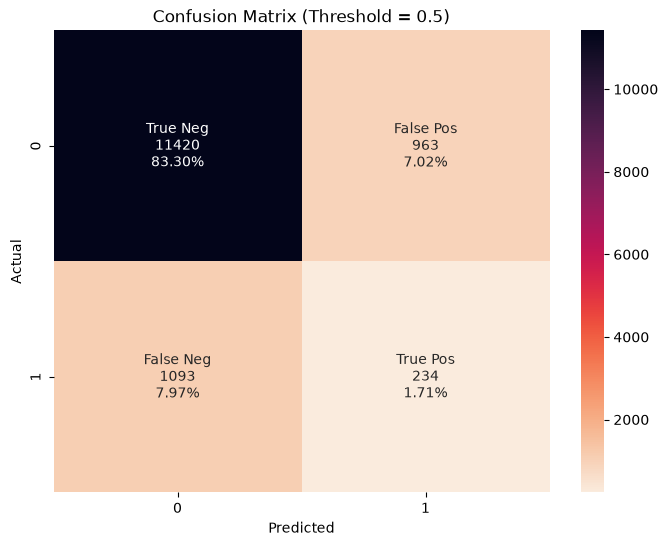


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.92      0.92     12383
           1       0.20      0.18      0.19      1327

    accuracy                           0.85     13710
   macro avg       0.55      0.55      0.55     13710
weighted avg       0.84      0.85      0.85     13710

ROC-AUC: 0.6542679723356053
PR-AUC: 0.1567400837032453
MCC: 0.10324380872816427

Experiment contact completed!
Experiment: interaction
Train: (54836, 41) (54836,)
Validation: (13710, 41) (13710,)

Train Distribution:
12-Month Default Flag
0    0.903239
1    0.096761
Name: proportion, dtype: float64

Validation Distribution:
12-Month Default Flag
0    0.903209
1    0.096791
Name: proportion, dtype: float64


ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/DL_ML_ev/lib/python3.12/site-packages/imblearn/pipeline.py", line 522, in fit
    self._final_estimator.

In [67]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

from catboost import CatBoostClassifier

experiment_results = {}

for name, X in X_experiments.items():

    print("=" * 40)
    print(f"Experiment: {name}")
    print("=" * 40)

    # 1. Separate Features and Target
    X_features = X.drop(columns=target_col)
    y_target = X["12-Month Default Flag"]

    # 2. Split Dataset
    X_train, X_test, y_train, y_test = Split_datamodel_func(
        X_features,
        y_target
    )

    # 3. Define Pipeline
    model = clone(cat_model)

    pipeline = Pipeline([
        ("undersampling", RandomUnderSampler(
            sampling_strategy=0.5,
            random_state=42
        )),
        ("classifier", model)
    ])

    # 4. Cross Validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    print("CV PR-AUC:", cv_scores)
    print("CV Mean:", cv_scores.mean())
    print("CV Std:", cv_scores.std())

    # 5. Fit Final Model
    # Pipeline resamples training data only
    pipeline.fit(X_train, y_train)

    # 6. Predict Probability
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # 7. Evaluation
    y_pred = model_evaluation(
        pipeline,
        X_test,
        y_test,
        threshold=0.5,
        y_prob=y_prob
    )

    # 8. Store Results
    experiment_results[name] = {
        "model": pipeline,
        "y_prob": y_prob,
        "cv_scores": cv_scores,
        "cv_mean": cv_scores.mean(),
        "cv_std": cv_scores.std(),
        "y_test": y_test,
        "y_pred": y_pred
    }

    print(f"\nExperiment {name} completed!")


##

##

## Submission

In [75]:
test_data

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,Company Size Category,Business Entity Type,Declared Annual Income,Payday,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211850001,20,1,1,301,301,640,1,1,1,3,0,3000000,10,0,0,200000,1,0,1,0,0,1,1,1,0
1,211850002,20,1,2,274,15,640,5,1,1,5,0,2700000,10,0,0,200000,1,40000,1,1,1,0,1,1,0
2,211850003,20,1,2,771,28,640,99,4,1,5,0,1500000,25,0,0,500000,4,50000,0,0,0,0,1,1,1
3,211870001,17,1,2,370,26,640,5,1,1,5,9,4200000,15,2,1000000,200000,4,54000,0,1,1,0,1,1,1
4,211880001,17,2,1,270,1,540,1,5,1,4,9,1400000,31,2,400000,150000,4,48000,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,215490262,20,1,1,268,3,540,99,1,1,2,0,3000000,15,0,0,200000,4,1000,0,0,0,0,1,1,0
137087,215490263,17,1,2,604,187,740,9,1,1,3,9,5500000,10,4,1800000,50000,1,90000,1,4,2,1,1,1,1
137088,215490264,20,1,1,496,70,440,8,1,1,5,0,4000000,27,2,1000000,200000,1,0,3,0,0,1,1,1,0
137089,215490265,18,1,1,409,409,240,1,1,1,3,9,5810000,28,2,1700000,200000,1,0,3,0,0,1,1,1,1


In [79]:
# 1. Predict
# Predict probability
y_prob = cat_clf.predict_proba(test_data[original_feature])[:, 1]

# Set threshold = 0.30
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

# 2. Create submission with ID from test set
submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_prob
})
submission[["12-Month Default Flag"]].value_counts()

12-Month Default Flag
0.370107                 4
0.547459                 3
0.580984                 3
0.482575                 3
0.421300                 3
                        ..
0.548255                 1
0.317620                 1
0.499675                 1
0.343484                 1
0.581896                 1
Name: count, Length: 136215, dtype: int64

In [80]:
target = '12-Month Default Flag'

# Count
print(submission[target].value_counts())

# Percentage
print(submission[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0.370107    4
0.547459    3
0.580984    3
0.482575    3
0.421300    3
           ..
0.548255    1
0.317620    1
0.499675    1
0.343484    1
0.581896    1
Name: count, Length: 136215, dtype: int64
12-Month Default Flag
0.370107    0.002918
0.547459    0.002188
0.580984    0.002188
0.482575    0.002188
0.421300    0.002188
              ...   
0.548255    0.000729
0.317620    0.000729
0.499675    0.000729
0.343484    0.000729
0.581896    0.000729
Name: proportion, Length: 136215, dtype: float64


In [81]:
# 3. Export CSV
submission.to_csv(
    'submission_complete.csv',
    float_format='%.2f',
    index=False
)

# 4. Check result
display(submission.head())

print("Shape:", submission.shape)
print("Missing values:\n", submission.isnull().sum())
print(submission[target].value_counts(normalize=True) * 100)

,ID,12-Month Default Flag
0,211850001,0.213800
1,211850002,0.478585
2,211850003,0.320735
3,211870001,0.614599
4,211880001,0.639557


Shape: (137091, 2)
Missing values:
 ID                       0
12-Month Default Flag    0
dtype: int64
12-Month Default Flag
0.370107    0.002918
0.547459    0.002188
0.580984    0.002188
0.482575    0.002188
0.421300    0.002188
              ...   
0.548255    0.000729
0.317620    0.000729
0.499675    0.000729
0.343484    0.000729
0.581896    0.000729
Name: proportion, Length: 136215, dtype: float64
